In [58]:
# Imports 

from pathlib import Path
import json
import os

import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.image as mpimg
import ipywidgets as widgets

from IPython.display import display, clear_output
import question_1

In [59]:
# Get the hockey data directory from Question 1
hockey_data_dir = os.environ.get("HOCKEY_DATA_DIR")

# Use the specified directory or the current working directory
DATA_DIR = Path(hockey_data_dir) if hockey_data_dir else Path.cwd()

# Detects and sorts all season folders
season_folders = sorted(
    [
        folder for folder in DATA_DIR.iterdir()
        if folder.is_dir()
        and len(folder.name) == 7
        and folder.name[4] == "-"
        and folder.name[:4].isdigit()
        and folder.name[5:].isdigit()
    ],
    key=lambda folder: int(folder.name[:4])
)

# Store each season's name and starting year for the dropdown
available_seasons = [
    (folder.name, int(folder.name[:4]))
    for folder in season_folders
]

# Making sure at least one season is available
if not available_seasons:
    raise FileNotFoundError(
        f"No season folders found in {DATA_DIR.resolve()}."
    )

print("Data directory:", DATA_DIR.resolve())
print("Available seasons:", [name for name, year in available_seasons])


Data directory: /Users/admin/Desktop/IFT6758/Projet 1/data_science_project/ift6758/data
Available seasons: ['2023-24']


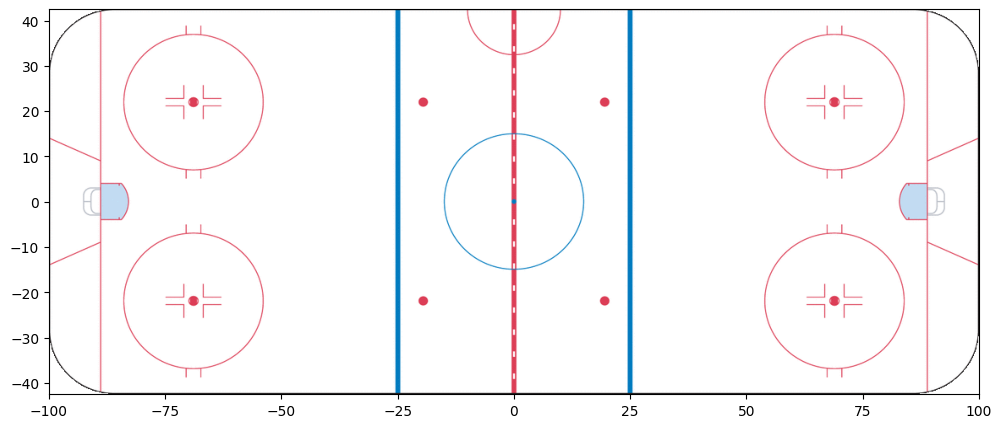

In [60]:
# Load the picture of the ice rink
# Path to the image 
rink_path = Path("../../figures/nhl_rink.png")

# Show the image 
if rink_path.exists():
    rink = mpimg.imread(rink_path)

    plt.figure(figsize=(12, 5))
    plt.imshow(
        rink,
        extent=(-100, 100, -42.5, 42.5),
        origin="lower",
        aspect="auto"
    )
# Error if image not found 
else:
    rink = None
    print("Ice rink image not found:", rink_path.resolve())


In [61]:
# Load the data for the selected season 

def load_season_games(year):

    season = f"{year}-{str(year + 1)[-2:]}"
    season_dir = DATA_DIR / season

    if not season_dir.exists():
        raise FileNotFoundError(
            f"The directory {season_dir} does not exist."
        )

    # Dictionary that stores the games 
    games = {}
    # Loop through all JSON files in the season folder
    for file_path in sorted(season_dir.glob("*.json")):

        with file_path.open("r", encoding="utf-8") as file:
            game_data = json.load(file)

        game_id = game_data.get("id")

        if game_id is None:
            game_id = int(file_path.stem)

        game_id = int(game_id)

        # 02 = regular season, 03 = playoffs
        game_type = str(game_id)[4:6]

        if game_type not in ("02", "03"):
            continue
            
        # Get list of the events from the game 
        plays = game_data.get("plays", [])

        if isinstance(plays, list):
            games[game_id] = {
                "game_id": game_id,
                "game_type": game_type,
                "plays": plays,
                "metadata": game_data
            }
    # Error if no games were found 
    if not games:
        raise ValueError(
            f"No games were found in {season_dir}."
        )

    return games

In [62]:
# Get the coordinates for the diffferent events 

def get_coordinates(play):

    details = play.get("details", {})

    if not isinstance(details, dict):
        details = {}

    x = details.get("xCoord")
    y = details.get("yCoord")

    try:
        if x is not None and y is not None:
            return float(x), float(y)
    except (TypeError, ValueError):
        pass

    return None, None

In [63]:
# Create the different widgets 

# Dropdown menu to select a season
# Most recent season is selected by default 
season_widget = widgets.Dropdown(
    options=available_seasons,
    value=available_seasons[-1][1],
    description="Season:"
)

# Buttons to choose between regular-season games and playoff games 
type_widget = widgets.ToggleButtons(
    options=[
        ("Regular season", "02"),
        ("Playoffs", "03")
    ],
    value="02",
    description="Game type:"
)

# Dropdown menu to select a game
game_widget = widgets.Dropdown(
    options=[],
    description="Game:",
    layout=widgets.Layout(width="400px")
)

# Slider to navigate through the events of the selected game
event_widget = widgets.IntSlider(
    value=0,
    min=0,
    max=0,
    step=1,                               # Move one event at a time 
    description="Event:",
    continuous_update=False,              # Update when the slider is released 
    readout=True,                         # Display the event index 
    layout=widgets.Layout(width="600px")
)

# Area where the game information, statistics and the rink are displayed 
output = widgets.Output()
# Store the loaded games of the selected season 
current_games = {}



In [64]:
# Display the different events and the statistics of the selected game 

def display_event(game_id, event_index):

    game = current_games[game_id]
    plays = game["plays"]
    metadata = game["metadata"]
   
    # Clear the different outputs before displaying new information 
    with output:
        clear_output(wait=True)

        if not plays:
            print("No events available.")
            return

        event_index = min(
            max(event_index, 0),
            len(plays) - 1
        )
        # Get the selected events 
        play = plays[event_index]

        # Getting the information for the different teams 
        home = metadata.get("homeTeam", {})
        away = metadata.get("awayTeam", {})
        
        #Get the name abbreviation and ID of each teams 
        home_name = home.get("abbrev", "Home")
        away_name = away.get("abbrev", "Away")

        home_id = home.get("id")
        away_id = away.get("id")

        print(
            f"Game ID: {game_id}; "
            f"{home_name} (home) vs {away_name} (away)"
        )

        # Calculate the different goals and shot on goals 
        # Initialize the statistics 
        home_goals = 0
        away_goals = 0
        home_sog = 0
        away_sog = 0
        
        # Loop through all the events in the game 
        for p in plays:

            event_type = (
                p.get("typeDescKey")
                or p.get("typeDesc")
                or ""
            ).lower()

            details_p = p.get("details", {})

            if not isinstance(details_p, dict):
                details_p = {}

            team_id = details_p.get("eventOwnerTeamId")

            # Count the goals and the shot on goals 
            if event_type in ("goal", "shot-on-goal"):

                if team_id == home_id:
                    home_sog += 1
                elif team_id == away_id:
                    away_sog += 1

            if event_type == "goal":

                if team_id == home_id:
                    home_goals += 1
                elif team_id == away_id:
                    away_goals += 1

        # Extracting the different periods in the game 
        period_info = play.get("periodDescriptor", {})

        if not isinstance(period_info, dict):
            period_info = {}
            
        # Get the period number and type
        period_number = period_info.get("number", "?")
        period_type = period_info.get("periodType", "")

        if period_type == "OT":
            period_label = "OT"
        elif period_type == "SO":
            period_label = "Shootout"
        else:
            period_label = f"Period {period_number}"

        # Display both teams statistics and the period 
        print(f"\n{period_label}")
        print(f"{'':15s} {'Home':12s} Away")
        print(f"{'Teams:':15s} {home_name:12s} {away_name}")
        print(f"{'Goals:':15s} {home_goals:<12} {away_goals}")
        print(
            f"{'Shots on goal:':15s} "
            f"{home_sog:<12} {away_sog}"
        )

        # Create the title for the event 
        event_type = (
            play.get("typeDescKey")
            or play.get("typeDesc")
            or "Unknown event"
        )

        title = event_type.replace("-", " ").capitalize()
        time_in_period = play.get("timeInPeriod", "?")
        # Display the event number, title and the time 
        print(f"\nEvent {event_index + 1}/{len(plays)}")
        print(title)
        print(f"{time_in_period} — {period_label}")

        # Display the ice rink 
        # Get the coordinates 
        x, y = get_coordinates(play)

        if rink is not None:

            fig, ax = plt.subplots(figsize=(12, 5))

            ax.imshow(
                rink,
                extent=(-100, 100, -42.5, 42.5),
                origin="lower",
                aspect="auto"
            )

            # Mark the event with a blue circle if coordinates are available 
            if x is not None and y is not None:

                ax.scatter(
                    x,
                    y,
                    color="blue",
                    s=120,
                    edgecolors="white",
                    linewidths=1.5,
                    zorder=5
                )

            else:
                print(
                    "\nNo coordinates are available "
                    "for this event."
                )

            ax.set_xlim(-100, 100)
            ax.set_ylim(-42.5, 42.5)
            ax.set_xlabel("Feet")
            ax.set_ylabel("Feet")

            ax.set_title(
                f"{title}\n"
                f"{time_in_period} — {period_label}"
            )

            plt.show()
            plt.close(fig)

        else:
            print("Ice rink image not found.")

        # Display the events data 
        print("\nEvent data:")
        print(json.dumps(play, indent=2, ensure_ascii=False))



In [65]:
# Update the game list based on the selected season 
def update_games(change=None):

    global current_games
    
    # Load all the games from the selected season 
    try:
        current_games = load_season_games(
            season_widget.value
        )

        selected_type = type_widget.value

        matching_games = sorted([
            game_id
            for game_id, game in current_games.items()
            if game["game_type"] == selected_type
        ])
    
        if not matching_games:

            game_widget.options = []

            with output:
                clear_output(wait=True)
                print("No games are available for this game type.")

            return

        game_widget.options = [
            (str(game_id), game_id)
            for game_id in matching_games
        ]
        # atomatically selects the first game in the list 
        game_widget.value = matching_games[0]

    except Exception as error:

        with output:
            clear_output(wait=True)
            print("Error:", error)

In [66]:
# Update the event slider when a different game is selected 
def update_event_slider(change=None):

    if game_widget.value is None:
        return

    game_id = game_widget.value
    plays = current_games[game_id]["plays"]

    event_widget.max = max(len(plays) - 1, 0)
    event_widget.value = 0
    # Display the forst event of the selected game 
    display_event(game_id, 0)

#Update the displayed event when the slider value changes
def update_display(change=None):

    if game_widget.value is not None:
        display_event(
            game_widget.value,
            event_widget.value
        )


In [ ]:
# Connect the widgets 
season_widget.observe(update_games, names="value")
type_widget.observe(update_games, names="value")
game_widget.observe(update_event_slider, names="value")
event_widget.observe(update_display, names="value")


# Display the interface, widgets.VBox() stacks widgets vertically
display(
    widgets.VBox([
        widgets.HTML(
            "<h3>Interactive NHL Game Explorer</h3>"
        ),
        season_widget,
        type_widget,
        game_widget,
        event_widget,
        output
    ])
)

update_games()




In [ ]:
# References : 
# Python pathlib: https://docs.python.org/3/library/pathlib.html
# Python json: https://docs.python.org/3/library/json.html
# Python os for mapping environment variables: https://docs.python.org/3/library/os.html#os.environ
# Matplotlib imshow to display images: https://matplotlib.org/stable/api/_as_gen/matplotlib.pyplot.imshow.html
# Matplotlib scatter plot for the blue circle: https://matplotlib.org/stable/api/_as_gen/matplotlib.axes.Axes.scatter.html
# ipywidgets documentation list: https://ipywidgets.readthedocs.io/en/stable/examples/Widget%20List.html
# ipywidgets VBox documentation : https://ipywidgets.readthedocs.io/en/stable/examples/Widget%20List.html#VBox
